# **Superstore Sales Demand Forecasting**

## Dataset

Retail operations di Amerika Serikat periode 2011 sampai 2014, terdiri dari 3 file:

| File | Isi |
|---|---|
|`superstore-orders-data.csv`|21 kolom: detail order, customer, sales, profit, shipping, produk, kategori produk|
|`superstore-returns-data.csv`|Pemetaan `Order ID` yang direturn|
|`superstore-people-data.csv`|Regional manager per `Region` (West, East, Central, South|

## Decision Design
|Keputusan|Pilihan|Alasan|
|---|---|---|
|Variabel target|`Sales` (nilai penjualan)|Permintaan penjualan diukur dalam nilai transaksi|
|Level agregasi|`Region` x `Category` per bulan|Total bulanan hanya 48 titik, terlalu sedikit untuk model berbasis fitur. Level ini menghasilkan 12 deret waktu dan sekitar 570 baris, sekaligus memanfaatkan tabel `People` (manajer regional)|
|Pembagian data|Berurutan waktu|Pembagian acak membuat model memakai informasi masa depan|
|Fitur|Lag dan rata-rata bergulir dari `Sales` bulan sebelumnya, serta kalender|`Quantity`, `Discount`, `Profit` bulan yang sama belum diketahui saat peramalan dibuat, sehingga tidak boleh dipakai langsung|



### Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
orders = pd.read_csv("../data/raw/superstore-orders-data.csv")
people = pd.read_csv("../data/raw/superstore-people-data.csv")
returns = pd.read_csv("../data/raw/superstore-returns-data.csv")

In [3]:
print("Orders :", orders.shape)
print("People :", people.shape)
print("Returns :", returns.shape)

Orders : (9994, 21)
People : (4, 2)
Returns : (296, 2)


# Data Wrangling
**Tujuan**: memastikan data bersih, tipe data benar, dan ketiga tabel tergabung dengan benar.

### Understanding the data

In [4]:
orders.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,11/9/2013,11/12/2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,11/9/2013,11/12/2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,6/13/2013,6/17/2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,10/11/2012,10/18/2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,10/11/2012,10/18/2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

Pada data orders disini, terdapat beberapa kolom yang belum rapi (masih ada jarak), dan tipe data yang kurang sesuai, seperti Order Date yang seharusnya datetime. Barisnya sudah bersih, alias tidak ada baris kosong.

In [6]:
orders.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [7]:
print("Nilai kosong per kolom:")
print(orders.isnull().sum())
print()
print("Baris duplikat:")
print(orders.duplicated().sum())

Nilai kosong per kolom:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Baris duplikat:
0


In [8]:
print(people.head())
print()
print(returns.head())

              Person   Region
0      Anna Andreadi     West
1        Chuck Magee     East
2     Kelly Williams  Central
3  Cassandra Brandow    South

  Returned        Order ID
0      Yes  CA-2014-153822
1      Yes  CA-2014-129707
2      Yes  CA-2011-152345
3      Yes  CA-2012-156440
4      Yes  US-2014-155999


### Formatting Column Names

Spasi dan tanda hubung pada nama kolom menyulitkan pemanggilan kolom di kode. Semua nama diseragamkan menjadi huruf dengan garis bawah, misalnya `Sub-Category` menjadi `Sub_Category`.

In [9]:
for df_ in (orders, people, returns):
    df_.columns = (df_.columns.str.strip()
                   .str.replace(" ", "_")
                   .str.replace("-", "_"))

In [10]:
required_column = ["Order_ID", "Order_Date", "Region", "Category", "Sub_Category", "Quantity",
                   "Sales", "Discount", "Profit"]

In [11]:
print("Kolom wajib yang tidak ditemukan:", [c for c in required_column if c not in orders.columns])
print()
print("Orders column :", list(orders.columns))
print("People column :", list(people.columns))
print("Returns column:", list(returns.columns))

Kolom wajib yang tidak ditemukan: []

Orders column : ['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit']
People column : ['Person', 'Region']
Returns column: ['Returned', 'Order_ID']


### Changing the date types

Setelah konversi, nilai minimum dan maksimum `Order_Date` harus berada pada rentang 2011 sampai 2014 sesuai deskripsi dataset.

In [12]:
orders["Order_Date"] = pd.to_datetime(orders["Order_Date"])
orders["Ship_Date"] = pd.to_datetime(orders["Ship_Date"])

print("Tanggal pesanan paling awal  :", orders["Order_Date"].min())
print("Tanggal pesanan paling akhir :", orders["Order_Date"].max())

Tanggal pesanan paling awal  : 2011-01-04 00:00:00
Tanggal pesanan paling akhir : 2014-12-31 00:00:00


#### Merging tables

Tabel `Returns` dipetakan ke `Orders` melalui `Order_ID`, sedangkan tabel `People` melalui `Region`. Jumlah baris sebelum dan sesudah penggabungan harus sama. Jika berbeda, terdapat kunci ganda yang perlu di telusuri.

In [13]:
# Hapus duplikat Order_ID pada dataset returns
returns = returns.drop_duplicates(subset="Order_ID")
n_awal = len(orders)

In [14]:
# Gabungkan hasil returns terbaru dengan dataset orders
orders = orders.merge(returns, on="Order_ID", how="left")

In [15]:
# Ubah Status returns yang tidak ada pada dataset orders menjadi "No"
orders["Returned"] = orders["Returned"].fillna("No")

In [16]:
# Gabungkan dataset people dengan orders
orders = orders.merge(people, on="Region", how="left")

In [17]:
# Mengecek baris dataset orders sebelum dan sesudah merge
print("Baris sebelum:", n_awal, "| sesudah:", len(orders))
# Periksa kunci penggabungan
assert n_awal == len(orders), "Jumlah baris berubah, periksa kunci penggabungan"

Baris sebelum: 9994 | sesudah: 9994


In [18]:
orders["Returned"].value_counts()

Returned
No     9194
Yes     800
Name: count, dtype: int64

### Create calendar features

In [19]:
orders["Year"] = orders["Order_Date"].dt.year
orders["Month"] = orders["Order_Date"].dt.month
orders["Year_Month"] = orders["Order_Date"].dt.to_period("M").dt.to_timestamp()

orders[["Order_Date", "Year", "Month", "Year_Month"]].head()

,Order_Date,Year,Month,Year_Month
0,2013-11-09,2013,11,2013-11-01
1,2013-11-09,2013,11,2013-11-01
2,2013-06-13,2013,6,2013-06-01
3,2012-10-11,2012,10,2012-10-01
4,2012-10-11,2012,10,2012-10-01


### Decisions on Handling Returns

Penjualan pada analisis ini didefinisikan sebagai nilai pesanan yang masuk, sehingga pesanan retur tetap dihitung (`include_returns = True`), yang disebut juga penjualan kotor. Ubah menjadi `False` untuk menghitung penjualan bersih dan bandingkan hasil akhirnya.

In [20]:
include_returns = True

if include_returns:
    demand_src = orders.copy()
else:
    demand_src = orders[orders["Returned"] == "No"].copy()

print("Baris yang dipakai:", len(demand_src))
print("Total Sales       :", round(demand_src["Sales"].sum(), 2))

Baris yang dipakai: 9994
Total Sales       : 2297200.86


### Task

1. Periksa apakah ada nilai `Sales` nol atau negatif, lalu tentukan cara penanganannya dan tulis alasannya.
2. Hitung persentase nilai `Sales` yang berstatus `Returned = Yes` terhadap total `Sales`, dan bandingkan dengan persentase jumlah pesanannya.
3. Buat kolom `Lead_Days` (selisih `Ship_Date` dan `Order_Date`) dan periksa apakah ada nilai yang tidak masuk akal.
4. Ubah tipe `Category`, `Region`, dan `Segment` menjadi `category`, lalu bandingkan penggunaan memori dengan `orders.info(memory_usage='deep')` sebelum dan sesudahnya.

<details>
<summary>Hint (buka jika diperlukan)</summary>

1. Gunakan `(orders["Sales"] <= 0).sum()` dan `describe()`. Pertimbangkan apakah nilai nol merupakan kesalahan input atau transaksi yang sah sebelum menghapusnya.
2. Persentase nilai memakai `sum()` pada `Sales` dengan filter `Returned == "Yes"`. Persentase jumlah pesanan memakai `nunique()` pada `Order_ID` karena satu pesanan dapat memiliki banyak baris.
3. Selisih dua kolom datetime menghasilkan `Timedelta`. Akses `.dt.days` untuk mengubahnya menjadi angka.
4. Gunakan `astype("category")` dan `memory_usage(deep=True).sum()`. Bagi hasilnya dengan `1024**2` untuk memperoleh satuan MB.

</details>

In [21]:
# Nilai Sales nol atau negatif

print("Sales <= 0:", (orders["Sales"] <= 0).sum())
print("Sales negatif:", (orders["Sales"] < 0).sum())

print(orders["Sales"].describe())

Sales <= 0: 0
Sales negatif: 0
count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64


**Hasil:** jika jumlahnya nol, tidak ada penanganan khusus yang diperlukan. Jika ada, periksa dahulu barisnya dengan `orders[orders["Sales"] <= 0]`. Nilai nol dapat berupa transaksi sah (misalnya barang promosi gratis) sehingga tidak otomatis dihapus. Nilai negatif biasanya menandakan koreksi atau retur yang tercatat sebagai baris tersendiri. Apa pun keputusannya, tulis alasannya pada catatan analisis.

In [22]:
# Persentase retur menurut nilai dan menurut jumlah pesanan

pct_nilai = 100 * orders.loc[orders["Returned"] == "Yes", "Sales"].sum() / orders["Sales"].sum()

n_pesanan = orders["Order_ID"].nunique()
n_retur = orders.loc[orders["Returned"] == "Yes", "Order_ID"].nunique()
pct_pesanan = 100 * n_retur / n_pesanan

print(f"Retur menurut nilai Sales    : {pct_nilai:.2f}%")
print(f"Retur menurut jumlah pesanan : {pct_pesanan:.2f}% ({n_retur} dari {n_pesanan} pesanan)" )

Retur menurut nilai Sales    : 7.86%
Retur menurut jumlah pesanan : 5.91% (296 dari 5009 pesanan)


**Hasil:** jika persentase menurut nilai lebih besar daripada menurut jumlah pesanan, pesanan yang diretur cenderung bernilai di atas rata-rata. Jika lebih kecil, retur lebih banyak terjadi pada pesanan bernilai kecil. Selisih keduanya menentukan seberapa besar perbedaan antara penjualan kotor dan penjualan bersih.

In [23]:
# Lead_Days column

orders["Lead_Days"] = (orders["Ship_Date"] - orders["Order_Date"]).dt.days

In [24]:
print(orders["Lead_Days"].describe())

count    9994.000000
mean        3.958875
std         1.747097
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Lead_Days, dtype: float64


In [25]:
print("Lead_Days negatif:", (orders["Lead_Days"] < 0).sum())
print("Lead_Days di atas 14 hari:", (orders["Lead_Days"] > 14).sum())

Lead_Days negatif: 0
Lead_Days di atas 14 hari: 0


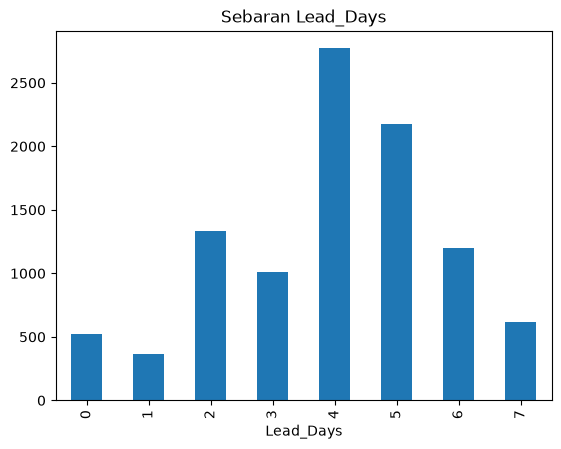

In [26]:
# Buat plot sebaran
orders["Lead_Days"].value_counts().sort_index().plot(kind="bar", title="Sebaran Lead_Days")

plt.show()

**Hasil:** nilai negatif tidak masuk akal karena pengiriman tidak mungkin mendahului pemesanan, sehingga baris tersebut perlu diperiksa. Nilai yang sangat besar juga perlu dicek terhadap `Ship_Mode`.

In [27]:
# Tipe data category dan penggunaan memori
sebelum = orders.memory_usage(deep=True).sum() / 1024**2

In [28]:
tmp = orders.copy()
for kol in ["Category", "Region", "Segment"]:
    tmp[kol] = tmp[kol].astype("category")

In [29]:
sesudah = tmp.memory_usage(deep=True).sum() / 1024**2

print(f"Sebelum: {sebelum:.2f} MB")
print(f"Sesudah: {sesudah:.2f} MB")
print(f"Penghematan: {100 * (1 - sesudah / sebelum):.1f}%")

Sebelum: 9.58 MB
Sesudah: 7.95 MB
Penghematan: 17.0%


**Hasil:** kolom teks dengan sedikit nilai unik sangat efisien jika disimpan sebagai `category` karena nilainya disimpan sekali dan baris hanya menyimpan kode. Pada dataset sekecil ini penghematan belum terasa penting, tetapi kebiasaan ini berguna pada data berukuran besar.

# Exploratory Data Analysis (EDA)

**Tujuan:** memahami pola tren, musiman, dan hubungan antarvariabel sebelum memodelkan. Temuan pada modul ini menjadi dasar pemilihan fitur dan pembenaran model.

### Monthly sales trends

In [30]:
# Buat variabel monthly dengan groupby
# demand_src hasil copy dari merge dataset orders, people, returns
monthly = demand_src.groupby("Year_Month")["Sales"].sum()

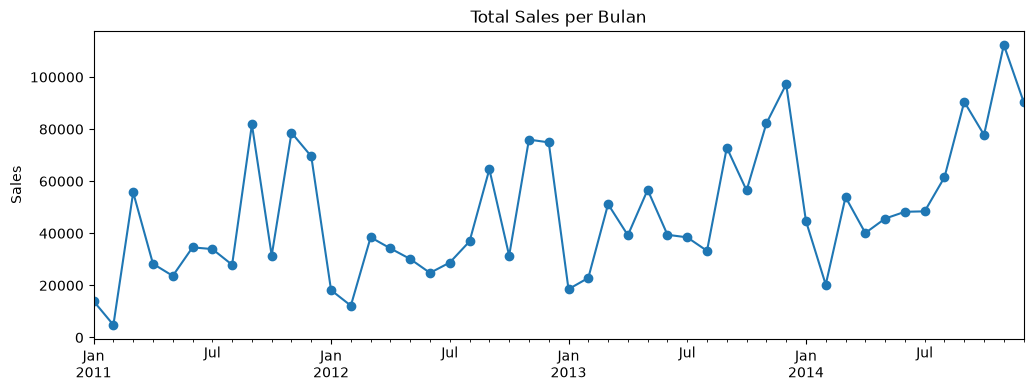

In [31]:
plt.figure(figsize=(12, 4))
monthly.plot(marker="o")
plt.title("Total Sales per Bulan")
plt.ylabel("Sales")
plt.xlabel("")
plt.show()

### Seasonal trends

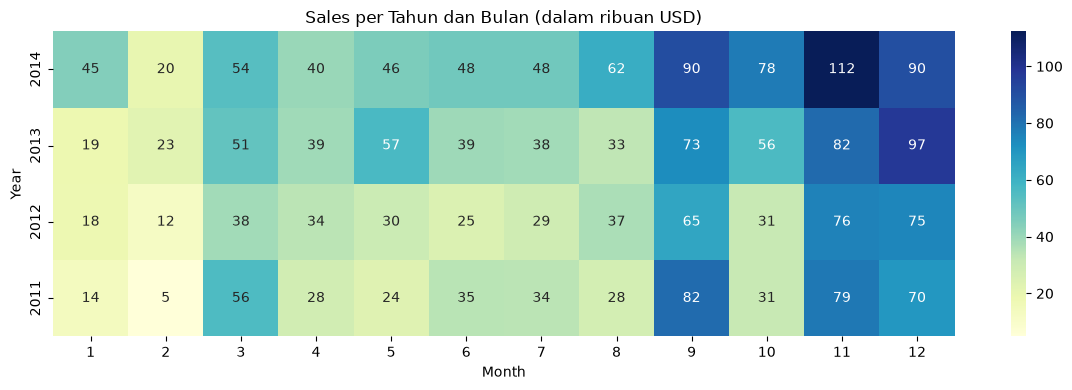

In [32]:
pivot = demand_src.pivot_table(index="Year", columns="Month",
                         values="Sales", aggfunc="sum") / 1000

pivot = pivot.sort_index(ascending=False)

plt.figure(figsize=(12, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Sales per Tahun dan Bulan (dalam ribuan USD)")
plt.tight_layout()
plt.show()

In [51]:
demand_src.groupby("Year")["Sales"].sum()

Year
2011    484247.4981
2012    470532.5090
2013    608473.8300
2014    733947.0232
Name: Sales, dtype: float64

In [55]:
print(pivot.mean(axis=1))

Year
2014    61.162252
2013    50.706153
2012    39.211042
2011    40.353958
dtype: float64


In [56]:
avg_month = pivot.loc[2014].mean()

In [61]:
selisih = (pivot.loc[2014, 11] - avg_month) / avg_month * 100
print(round(avg_month, 2), selisih.round(1))

61.16 83.7


### Sales per category, region, and sub-category

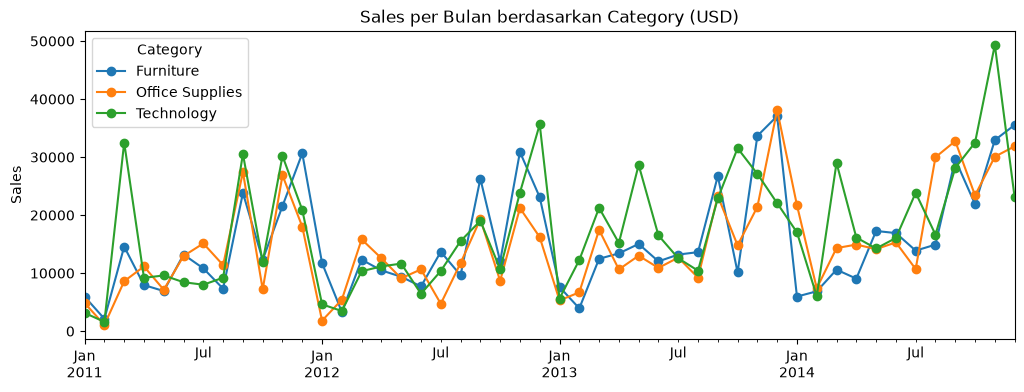

In [33]:
# Plot berdasarkan category

by_categ = demand_src.groupby(["Year_Month", "Category"])["Sales"].sum().unstack("Category")

# by_categ["Technology"].plot(figsize=(12,4), marker="o", title="Sales per Bulan berdasarkan Category")
by_categ.plot(figsize=(12,4), marker="o", title="Sales per Bulan berdasarkan Category (USD)")
plt.ylabel("Sales")
plt.xlabel("")
plt.show()

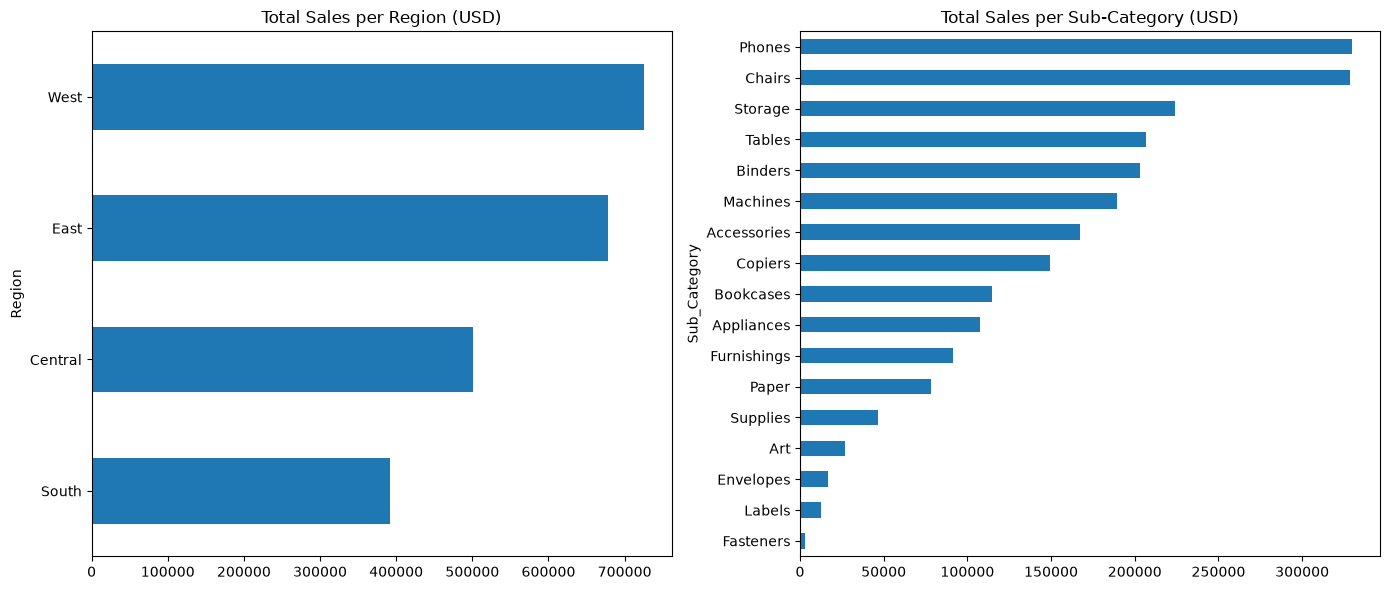

In [34]:
# Plot berdasarkan region dan sub-category, dijadikan berdampingan

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot sales per region
sales_region = demand_src.groupby("Region")["Sales"].sum().sort_values()
sales_region.plot(kind="barh", ax=axes[0], title="Total Sales per Region (USD)")

# Plot sales per sub-category
sales_subcateg = demand_src.groupby("Sub_Category")["Sales"].sum().sort_values()
sales_subcateg.plot(kind="barh", ax=axes[1], title="Total Sales per Sub-Category (USD)")

plt.tight_layout()
plt.show()

In [83]:
# Total penjualan
total_sales = demand_src["Sales"].sum()

In [91]:
# Total penjualan berdasarkan region
print((sales_region.loc["West"] / total_sales * 100).round(2))
print((sales_region.loc["East"] / total_sales * 100).round(2))
print((sales_region.loc["Central"] / total_sales * 100).round(2))
print((sales_region.loc["South"] / total_sales * 100).round(2))

31.58
29.55
21.82
17.05


In [97]:
# Total penjualan berdasarkan category
print((by_categ["Technology"].sum() / total_sales * 100).round(2))
print((by_categ["Furniture"].sum() / total_sales * 100).round(2))
print((by_categ["Office Supplies"].sum() / total_sales * 100).round(2))

36.4
32.3
31.3


### Correlation and distribution

Nilai `Sales` per baris pesanan cenderung sangat miring ke kanan, sehingga histogram memakai skala logaritmik pada sumbu horizontal.

In [35]:
# Konfirmasi menceng ke kanan (right-skewed) sebelum membuat histogram
# Dilihat hasil dari skewness bernilai positif besar
# Dan, mean yang jauh lebih tinggi dibanding median

print(demand_src["Sales"].describe())
print("Median:", demand_src["Sales"].median())
print("Skewness:", demand_src["Sales"].skew())

count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64
Median: 54.489999999999995
Skewness: 12.97275234181623


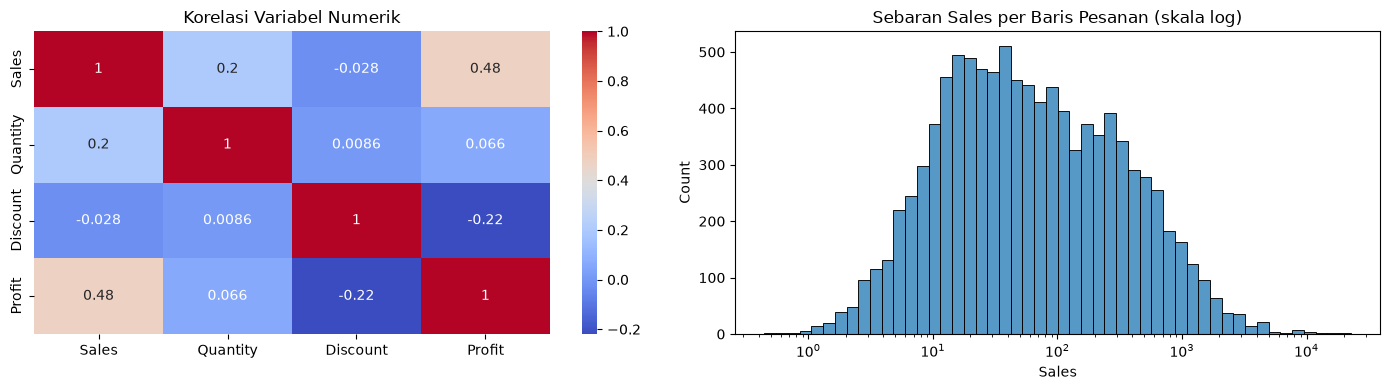

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gunakan heat map untuk visualisasi korelasi variabel numerik
sns.heatmap(demand_src[["Sales", "Quantity", "Discount", "Profit"]].corr(),
            annot=True, cmap="coolwarm", ax=axes[0])

axes[0].set_title("Korelasi Variabel Numerik")

# Gunakan histogram untuk visualisasi sebaran per baris pesanan
sns.histplot(demand_src["Sales"], bins=50, log_scale=True, ax=axes[1])

axes[1].set_title("Sebaran Sales per Baris Pesanan (skala log)")

plt.tight_layout()
plt.show()

### Task

1. Bandingkan pola musiman antar-`Region` dengan satu grafik garis per wilayah.
2. Kelompokkan `Discount` menjadi tiga kelompok (0, di atas 0 sampai 20 persen, di atas 20 persen) dan bandingkan rata-rata `Sales` per baris pesanan pada tiap kelompok.
3. Hitung pertumbuhan penjualan tahunan (year over year) per bulan dan periksa apakah pertumbuhannya stabil.
4. Hitung koefisien variasi (standar deviasi dibagi rata-rata) penjualan bulanan tiap kombinasi `Region` dan `Category`, lalu tentukan kombinasi yang paling fluktuatif.
5. Tulis tiga insight bisnis, masing-masing dalam satu paragraf pendek.

<details>
<summary>Hint (buka jika diperlukan)</summary>

1. Jumlahkan `Sales` per `Month` dan `Region` dengan `pivot_table`, lalu bagi tiap kolom dengan rata-ratanya agar wilayah berskala berbeda dapat dibandingkan (indeks musiman).
2. Gunakan `pd.cut` dengan `bins=[-0.01, 0, 0.2, 1]` lalu `groupby(...).agg(["mean", "median", "count"])`. Ingat bahwa `Sales` sudah dihitung setelah diskon.
3. Metode `pct_change(12)` pada deret bulanan menghitung perubahan terhadap 12 bulan sebelumnya.
4. Ubah data menjadi tabel lebar dengan `unstack`, lalu hitung `std(axis=1) / mean(axis=1)`.
5. Gunakan pola tiga bagian: temuan, bukti angka, dan implikasi bisnis.

</details>

#### Seasonal trends per-region

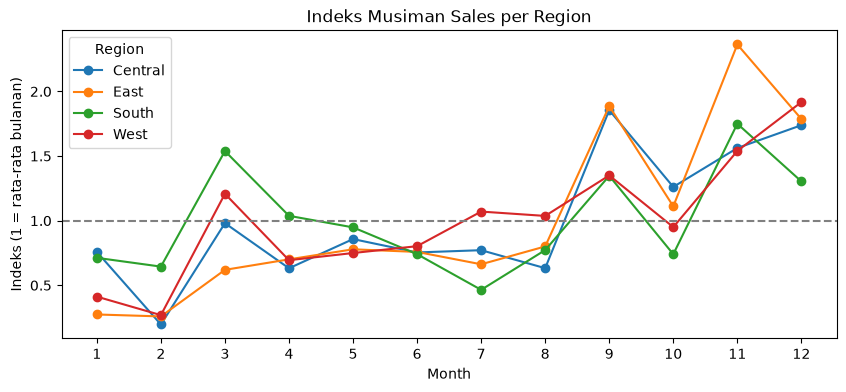

In [37]:
seas = demand_src.pivot_table(index="Month", columns="Region", values="Sales",
                              aggfunc="sum")
seas_idx = seas / seas.mean()

seas_idx.plot(marker="o", figsize=(10,4), title="Indeks Musiman Sales per Region")
plt.axhline(1, color="gray", linestyle="--")
plt.ylabel("Indeks (1 = rata-rata bulanan)")
plt.xticks(range(1, 13))
plt.show()

**Hasil:** nilai di atas 1 berarti bulan tersebut lebih tinggi daripada rata-rata bulanan wilayah itu. Jika puncak dan lembah muncul pada bulan yang sama di semua wilayah, pola musiman bersifat umum dan satu fitur `Month` sudah memadai. Jika berbeda, interaksi antara wilayah dan bulan perlu dipertimbangkan.

#### Discount group and Sales mean per order row

In [38]:
tmp = demand_src.assign(Discount_group = pd.cut(demand_src["Discount"],
                                                bins=[-0.1, 0, 0.2, 1],
                                                labels=["Tanpa diskon", "Di atas 0 sampai 20%",
                                                       "Di atas 20%"]))

In [39]:
print(tmp.groupby("Discount_group", observed=True)["Sales"].agg(["mean", "median", "count"]).round(2))

                        mean  median  count
Discount_group                             
Tanpa diskon          226.74   53.55   4798
Di atas 0 sampai 20%  222.59   56.16   3803
Di atas 20%           260.42   44.40   1393


In [40]:
print(pd.crosstab(index=tmp["Discount_group"], columns=tmp["Category"]).round(3))
print()
print(pd.crosstab(index=tmp["Discount_group"], columns=tmp["Category"],
                 normalize="index").round(3))

Category              Furniture  Office Supplies  Technology
Discount_group                                              
Tanpa diskon                836             3129         833
Di atas 0 sampai 20%        743             2217         843
Di atas 20%                 542              680         171

Category              Furniture  Office Supplies  Technology
Discount_group                                              
Tanpa diskon              0.174            0.652       0.174
Di atas 0 sampai 20%      0.195            0.583       0.222
Di atas 20%               0.389            0.488       0.123


**Hasil:** `Sales` pada dataset ini sudah dihitung setelah diskon, sehingga rata-rata yang lebih rendah pada diskon tinggi belum berarti diskon menurunkan penjualan. Tabel silang kedua menunjukkan apakah kelompok diskon tertentu didominasi kategori produk tertentu, yang dapat menjadi penyebab perbedaan rata-rata. Kesimpulan sebab akibat tidak dapat ditarik dari perbandingan sederhana ini.

#### Growth year over year (YoY)

In [41]:
bulanan = demand_src.groupby("Year_Month")["Sales"].sum()

In [42]:
# Menghitung persentase penjualan berdasarkan 12 bulan sebelumnya
yoy = bulanan.pct_change(12).dropna() * 100

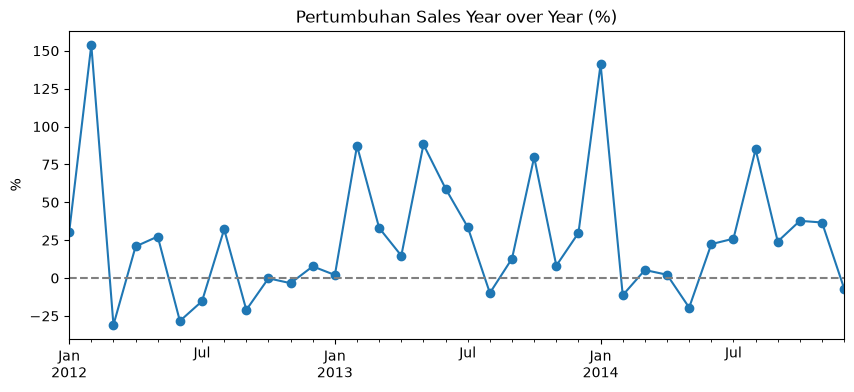

count     36.00
mean      26.52
std       43.14
min      -30.93
25%       -0.96
50%       21.62
75%       34.39
max      153.83
Name: Sales, dtype: float64


In [43]:
yoy.plot(marker="o", figsize=(10,4), title="Pertumbuhan Sales Year over Year (%)")
plt.axhline(0, color="gray", linestyle="--")
plt.ylabel("%")
plt.xlabel("")
plt.show()

print(yoy.describe().round(2))

|Ukuran|Nilai|Arti|
|---|---|---|
|count|36.00|Ada 36 bulan yang punya nilai YoY|
|mean|26.52|Rata-rata pertumbuhan YoY (%)|
|std|43.14|Sebaran data sangat besar|
|min|-30.93|Penurunan terdalam (%)|
|25%|-0.96|Seperempat bulan pertumbuhannya di bawah sekitar -1%|
|50%|21.61|Nilai tengah (median)|
|75%|34.39|Tiga perempat bulan pertumbuhannya di bawah 34,39%|
|max|153.83|Pertumbuhan persentase penjualan tertinggi (%)|


**Hasil:** pertumbuhan yang berkisar pada rentang sempit menunjukkan tren yang stabil, sedangkan simpangan baku besar menunjukkan tren yang tidak konsisten sehingga fitur `Year` saja kurang untuk menangkapnya. Perhatikan juga bahwa data baru tersedia mulai bulan ke-13 karena memerlukan pembanding 12 bulan sebelumnya.

#### Coefficient of variantion (CV) per Region and Category


In [44]:
lebar = (demand_src.groupby(["Region", "Category", "Year_Month"])["Sales"].sum()
    .unstack("Year_Month").fillna(0))

In [45]:
cv = (lebar.std(axis=1) / lebar.mean(axis=1)).sort_values(ascending=False)
print(cv.round(3))

Region   Category       
South    Technology         1.497
Central  Technology         1.060
East     Technology         1.046
Central  Office Supplies    0.885
South    Furniture          0.849
East     Furniture          0.807
South    Office Supplies    0.773
East     Office Supplies    0.738
West     Office Supplies    0.731
         Technology         0.723
Central  Furniture          0.708
West     Furniture          0.699
dtype: float64


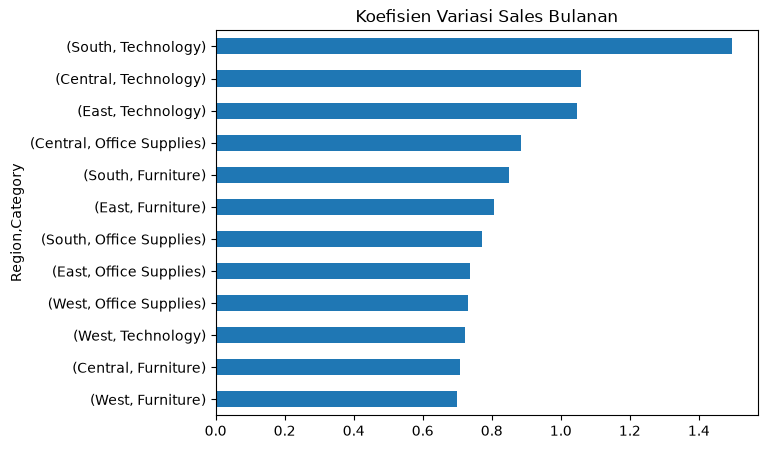

In [46]:
cv.sort_values().plot(kind="barh", figsize=(7, 5), title=("Koefisien Variasi Sales Bulanan"))
plt.show()

**Hasil:** semakin tinggi koefisien variasi, semakin tidak stabil penjualan bulanannya dan semakin sulit diramal. Kombinasi teratas pada daftar ini patut diperiksa lagi pada Solusi 4.1, apakah memang juga memiliki galat prediksi terbesar.

#### Business insight

1. **Tren dan musiman:** Penjualan bulanan menunjukkan meningkat dari tahun 2013 (608k USD) ke tahun 2014 (733k USD) dengan puncak berulang pada bulan September - Desember. Pada bulan November tahun 2014, penjualan bulan tersebut mencapai 112.000 USD atau 83,7% di atas rata-rata bulanan. Pola ini mengindikasikan perlunya persiapan stok dan promosi sebelum bulan September.

2. **Perbedaan region atau category:** Kombinasi Region West dan Category Technology memberi kontribusi terbesar dengan West(31,58%) dan Technology(36,40%) dari total penjualan, sedangkan Region South dan Category Technology memiliki koefisien variasi tertinggi sebesar 1,497. Kombinasi fluktuatif ini memerlukan perencanaan permintaan yang lebih hati-hati dibanding kombinasi yang relatif lebih stabil.

3. **Diskon dan retur:** Pesanan dengan diskon di atas 20 persen berjumlah 1393 baris dengan rata-rata `Sales` 260,42 USD, dibanding 226,74 USD pada pesanan tanpa diskon. Perbedaan ini perlu diinterpretasikan bersama komposisi kategori sebelum menyimpulkan efek diskon

   